# Laboratorio · Predecir propinas con Python
**Regresión lineal · Ejercicio individual**

**Dataset:** `tips.csv`, 244 cuentas de restaurante. [Ver dataset en Kaggle](https://www.kaggle.com/datasets/sakshisatre/tips-dataset).

**Problema:** estimar `tip` (propina en USD) a partir de `total_bill` (cuenta en USD) y después comprobar si `size` (número de personas) aporta valor.

**Instrucciones:** ejecutar las actividades en orden, completar las celdas de código y responder las preguntas con resultados propios. El archivo CSV debe estar junto al notebook.

## 01 · Explorar el CSV
**Objetivo.** Cargar `tips.csv` y mostrar **cinco filas**, dimensiones, valores faltantes y resumen numérico.

*Pista:* `pd.read_csv()`, `.head()`, `.shape`, `.isna().sum()`, `.describe()`.

**Resultado esperado:** Una tabla y el resumen inicial.

In [1]:
import pandas as pd

# Carga y revisión inicial de los datos.
datos = pd.read_csv("tips.csv")

print("Filas y columnas:", datos.shape)
display(datos.head())

print("Valores faltantes:")
print(datos.isna().sum())

display(datos.describe())

Filas y columnas: (244, 7)


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


Valores faltantes:
total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64


,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000


## 02 · Separar entradas y objetivo
**Objetivo.** Crear `X` con la cuenta total (`total_bill`) y `y` con la propina real (`tip`). Mostrar sus primeras filas y dimensiones.

*Pista:* `datos[["total_bill"]]` devuelve una tabla; `datos["tip"]` devuelve la serie objetivo.

**Resultado esperado:** Entradas y objetivos claramente identificados.

In [2]:
# Separa la entrada (cuenta total) del objetivo (propina).
X = datos[["total_bill"]]
y = datos["tip"]

print("Forma de X:", X.shape, "| Forma de y:", y.shape)
display(pd.DataFrame({
    "X: total_bill (USD)": X["total_bill"],
    "y: tip (USD)": y,
}).head())

Forma de X: (244, 1) | Forma de y: (244,)


,X: total_bill (USD),y: tip (USD)
0,16.99,1.01
1,10.34,1.66
2,21.01,3.50
3,23.68,3.31
4,24.59,3.61


## 03 · Crear entrenamiento y prueba
**Objetivo.** Reservar el 25 % de los registros para evaluar, usando `random_state=42`. Mostrar cuántas filas quedan en cada conjunto.

*Pista:* `train_test_split()` del módulo `sklearn.model_selection`.

**Resultado esperado:** Tamaños de `X_train`, `X_test`, `y_train`, `y_test`.

In [3]:
from sklearn.model_selection import train_test_split

# Reserva el 25 % de los registros para evaluar.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
)

print("X_train:", X_train.shape)
print("X_test: ", X_test.shape)
print("y_train:", y_train.shape)
print("y_test: ", y_test.shape)

X_train: (183, 1)
X_test:  (61, 1)
y_train: (183,)
y_test:  (61,)


## 04 · Entrenar y predecir
**Objetivo.** Crear una regresión, ajustarla con entrenamiento y predecir las propinas del conjunto de prueba. Mostrar cinco predicciones.

*Pista:* `LinearRegression()`, `.fit()`, `.predict()`.

**Resultado esperado:** Cinco importes estimados.

In [4]:
from sklearn.linear_model import LinearRegression

# Entrena el modelo y predice las propinas del conjunto de prueba.
modelo = LinearRegression()
modelo.fit(X_train, y_train)
pred = modelo.predict(X_test)

print(f"Pendiente: {modelo.coef_[0]:.4f}")
print(f"Intercepto: {modelo.intercept_:.4f}")
print("Cinco predicciones (USD):", [round(float(p), 2) for p in pred[:5]])

Pendiente: 0.1094
Intercepto: 0.8616
Cinco predicciones (USD): [3.03, 1.82, 3.55, 3.69, 2.28]


## 05 · Evaluar los errores
**Objetivo.** Calcular **MAE, MSE, RMSE y R²** sobre los datos de prueba e imprimir sus valores.

*Pista:* `sklearn.metrics`; para RMSE se puede usar `mse ** 0.5`.

**Resultado esperado:** Cuatro indicadores numéricos.

In [5]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

# Calcula las cuatro métricas sobre el conjunto de prueba.
mae = mean_absolute_error(y_test, pred)
mse = mean_squared_error(y_test, pred)
rmse = mse ** 0.5
r2 = r2_score(y_test, pred)

print(f"MAE:  {mae:.4f} USD")
print(f"MSE:  {mse:.4f} USD²")
print(f"RMSE: {rmse:.4f} USD")
print(f"R²:   {r2:.4f}")

MAE:  0.6522 USD
MSE:  0.7449 USD²
RMSE: 0.8631 USD
R²:   0.4401


## 06 · Graficar datos y predicción
**Objetivo.** Construir una tabla de cinco valores reales y predichos. Dibujar los puntos reales y la recta del modelo, con nombres en los ejes y leyenda.

*Pista:* `pd.DataFrame()`, `plt.scatter()`, `plt.plot()`; ordenar X solo para dibujar la línea.

**Resultado esperado:** Tabla comparativa y gráfico.

,Real,Predicho
0,3.18,3.03
1,2.00,1.82
2,2.00,3.55
3,5.16,3.69
4,2.00,2.28


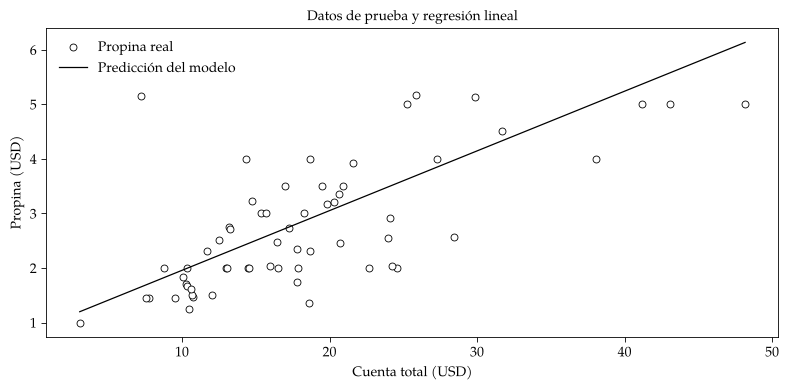

In [6]:
import matplotlib.pyplot as plt

# Estilo común para todas las figuras (serif, blanco y negro, líneas finas).
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": [
        "Palatino Linotype",
        "Palatino",
        "Book Antiqua",
        "TeX Gyre Pagella",
        "DejaVu Serif",
    ],
    "font.size": 10,
    "axes.titlesize": 10,
    "axes.labelsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "black",
    "axes.labelcolor": "black",
    "text.color": "black",
    "xtick.color": "black",
    "ytick.color": "black",
    "axes.linewidth": 0.6,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "lines.linewidth": 0.9,
    "patch.linewidth": 0.6,
    "axes.grid": False,
})

# Tabla comparativa de cinco valores reales y predichos.
display(pd.DataFrame({
    "Real": y_test.to_numpy()[:5],
    "Predicho": pred[:5],
}).round(2))

# Se ordena X solo para dibujar la recta.
orden = X_test.sort_values("total_bill")

plt.figure(figsize=(8, 4))
plt.scatter(
    X_test["total_bill"],
    y_test,
    s=25,
    facecolors="white",
    edgecolors="black",
    linewidths=0.6,
    label="Propina real",
)
plt.plot(
    orden["total_bill"],
    modelo.predict(orden),
    color="black",
    linewidth=0.9,
    label="Predicción del modelo",
)
plt.xlabel("Cuenta total (USD)")
plt.ylabel("Propina (USD)")
plt.title("Datos de prueba y regresión lineal")
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

## 07 · Inspeccionar residuos
**Objetivo.** Calcular `real − predicho`; graficar los residuos contra las predicciones, con una línea horizontal en cero.

*Pista:* `.to_numpy()`, `plt.scatter()`, `plt.axhline(0)`.

**Resultado esperado:** Gráfico de residuos.

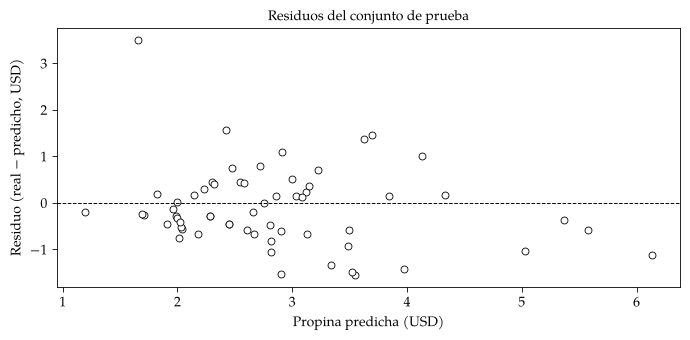

Residuo mínimo: -1.55 USD | máximo: 3.50 USD


In [7]:
# Residuo = real - predicho.
residuos = y_test.to_numpy() - pred

plt.figure(figsize=(7, 3.5))
plt.scatter(
    pred,
    residuos,
    s=25,
    facecolors="white",
    edgecolors="black",
    linewidths=0.6,
)
plt.axhline(0, color="black", linewidth=0.7, linestyle="--")
plt.xlabel("Propina predicha (USD)")
plt.ylabel("Residuo (real − predicho, USD)")
plt.title("Residuos del conjunto de prueba")
plt.tight_layout()
plt.show()

print(f"Residuo mínimo: {residuos.min():.2f} USD | máximo: {residuos.max():.2f} USD")

## 08 · Comparar una y dos entradas
**Objetivo.** Entrenar un segundo modelo usando `total_bill` y `size` juntos. Comparar **MAE, RMSE y R²** con el modelo inicial.

*Pista:* Definir `X2` con dos columnas y repetir la partición con el mismo `random_state`.

**Resultado esperado:** Comparación numérica de ambos modelos.

In [8]:
# Segundo modelo: total_bill + size, con la misma partición (random_state=42).
X2 = datos[["total_bill", "size"]]
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2,
    y,
    test_size=0.25,
    random_state=42,
)

modelo2 = LinearRegression()
modelo2.fit(X2_train, y2_train)
pred2 = modelo2.predict(X2_test)

mae2 = mean_absolute_error(y2_test, pred2)
rmse2 = mean_squared_error(y2_test, pred2) ** 0.5
r2_2 = r2_score(y2_test, pred2)

print("Coeficientes (total_bill, size):", modelo2.coef_.round(4))
display(pd.DataFrame(
    {
        "MAE": [mae, mae2],
        "RMSE": [rmse, rmse2],
        "R²": [r2, r2_2],
    },
    index=["Modelo 1: total_bill", "Modelo 2: total_bill + size"],
).round(4))

Coeficientes (total_bill, size): [0.095  0.2418]


,MAE,RMSE,R²
Modelo 1: total_bill,0.6522,0.8631,0.4401
Modelo 2: total_bill + size,0.6734,0.8799,0.4180


## Preguntas de desarrollo
Responder con los resultados obtenidos y, cuando corresponda, hacer referencia a los gráficos.

1. ¿Qué información contiene `X` y cuál es el objetivo `y`? ¿Qué cambia en la entrada cuando se agrega `size`?
2. ¿Cómo interpretar el MAE del primer modelo en **dólares de propina**? Dar un ejemplo de su significado.
3. ¿Qué diferencia existe entre MAE y RMSE? ¿Qué sugiere que RMSE sea mayor?
4. ¿Qué representa el R² obtenido? Explicar por qué **no** es un porcentaje de predicciones correctas.
5. ¿Qué se observa en el gráfico de residuos? ¿Hay valores especialmente alejados de cero?
6. ¿El modelo con dos entradas mejora los resultados en test? Justificar con MAE, RMSE y R² y proponer una explicación posible.

### Respuestas

**1.** `X` contiene la cuenta total del restaurante (`total_bill`, en USD) y es la información disponible para predecir; `y` es la propina real (`tip`, en USD), el valor que se quiere estimar. Ambas tienen 244 registros. Al agregar `size`, `X` pasa de una columna a dos (de forma `(244, 1)` a `(244, 2)`): el modelo recibe además el número de personas de la mesa y combina ambas variables para predecir el mismo `y`.

**2.** El MAE del primer modelo es de **0,65 USD**. Significa que, en promedio, la propina predicha se aleja unos 65 centavos de dólar de la propina real del conjunto de prueba. Por ejemplo, si una mesa dejó realmente 3,00 USD, el modelo suele predecir un valor entre 2,35 y 3,65 USD. Frente a una propina media de 2,75 USD, es un error de tamaño considerable.

**3.** El MAE promedia las distancias absolutas, así que todos los errores pesan lo mismo; el RMSE eleva los errores al cuadrado antes de promediar y luego saca la raíz, por lo que **penaliza más los errores grandes**. Ambos quedan en dólares. Aquí RMSE = 0,86 USD > MAE = 0,65 USD, lo que sugiere que hay algunos errores grandes (propinas muy por encima de lo predicho) que aumentan el RMSE más que el MAE. Si ambos fueran iguales, todos los errores serían de la misma magnitud.

**4.** El R² del primer modelo es de **0,44**: el modelo explica cerca del 44 % de la variabilidad de las propinas en el conjunto de prueba, es decir, reduce en ese porcentaje el error que se tendría al predecir siempre la propina promedio. **No es un porcentaje de predicciones correctas**, porque en una regresión la predicción es un número continuo y casi nunca coincide exactamente con el real; R² compara la suma de errores cuadrados del modelo (SSE) con la de la referencia de la media (SST) mediante R² = 1 − SSE/SST. El 56 % restante corresponde a variabilidad que `total_bill` no explica (generosidad, calidad del servicio, etc.).

**5.** Los residuos se reparten alrededor de la línea en cero, sin una curva clara ni una tendencia marcada, lo que indica que una recta es una aproximación razonable. Van de aproximadamente −1,55 a +3,50 USD. Sí hay un valor especialmente alejado de cero: un residuo de +3,50 USD con una propina predicha de solo ≈1,7 USD (una cuenta muy baja, de 7,25 USD, que dejó 5,15 USD de propina), además de otros residuos positivos cercanos a +1,5 USD. Los residuos negativos son más acotados (hasta ≈−1,5 USD). Estos pocos errores grandes explican por qué el RMSE supera al MAE.

**6.** **No, el modelo con dos entradas no mejora en test.** Con `total_bill` + `size` se obtiene MAE = 0,67 (antes 0,65), RMSE = 0,88 (antes 0,86) y R² = 0,42 (antes 0,44): los dos errores suben ligeramente y el R² baja. Una explicación posible es que `size` está correlacionada con `total_bill` (r ≈ 0,60: más personas implica una cuenta más alta), por lo que aporta poca información nueva; además, el conjunto de prueba es pequeño (61 filas), así que la diferencia es mínima y puede deberse a la partición concreta. Agregar una variable casi redundante puede ajustar un poco de ruido del entrenamiento sin mejorar la generalización.